# A First Look at Data

Exploratory Data Analysis (**EDA**) is the detective work you do *before* modelling or
drawing conclusions. Its goal is simple:

> **Get to know your data — what's in it, what it looks like, and whether you can trust it.**

This is the gentlest notebook in the module. We just *look* at a dataset using the
handful of commands every analyst runs in the first five minutes.

### What you will learn

| Section | Topic |
|---------|-------|
| 1 | Loading a dataset into a pandas DataFrame |
| 2 | Inspecting rows with `head`, `tail`, `sample` |
| 3 | The size and column names of a dataset |
| 4 | Column data types and spotting missing data (`info`) |
| 5 | Summary statistics (`describe`) |
| 6 | Telling numeric and categorical columns apart |

**Dataset — Palmer Penguins.** Body measurements of **344 penguins** from **three
species** (Adelie, Chinstrap, Gentoo) on three islands in the Palmer Archipelago,
Antarctica. A friendly, modern dataset with a mix of numeric and categorical columns and
some real missing values.
        

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
plt.rcParams["figure.dpi"] = 110

print("Setup complete.")

Setup complete.


---
## Section 1 — Loading the Data

A dataset is loaded into a **DataFrame** — pandas' table-like object, conventionally
named `df`. Each row is one penguin; each column is one attribute.

| Column | Meaning |
|--------|---------|
| `species` | Penguin species: Adelie, Chinstrap, or Gentoo |
| `island` | Island where it was observed: Biscoe, Dream, or Torgersen |
| `bill_length_mm` | Length of the bill (beak), in millimetres |
| `bill_depth_mm` | Depth (thickness) of the bill, in millimetres |
| `flipper_length_mm` | Flipper length, in millimetres |
| `body_mass_g` | Body mass, in grams |
| `sex` | Male or Female |
        

In [4]:
# The Palmer Penguins dataset ships with seaborn — no download needed.
df = sns.load_dataset("penguins")
print(f"Shape: {df.shape}")
df.head()

Shape: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


The table above shows the **first 5 rows** (`df.head()`). *Always look at your data first.*

---
## Section 2 — Peeking at Rows

- `df.head(n)` — the **first** `n` rows (default 5)
- `df.tail(n)` — the **last** `n` rows
- `df.sample(n)` — `n` **random** rows (a good unbiased feel)
        

In [5]:
df.tail(3)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female
343,Gentoo,Biscoe,49.9,16.1,213.0,5400.0,Male


In [6]:
df.sample(5, random_state=1)   # random_state makes the result repeatable

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
306,Gentoo,Biscoe,43.4,14.4,218.0,4600.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
291,Gentoo,Biscoe,46.4,15.6,221.0,5000.0,Male
102,Adelie,Biscoe,37.7,16.0,183.0,3075.0,Female
289,Gentoo,Biscoe,50.7,15.0,223.0,5550.0,Male


---
## Section 3 — How Big Is It?

`df.shape` returns `(number_of_rows, number_of_columns)`, and `df.columns` lists the
column names.
        

In [7]:
print('Rows, columns:', df.shape)
df.columns

Rows, columns: (344, 7)


Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex'],
      dtype='object')

---
## Section 4 — Column Types and Missing Data

`df.info()` is a quick health check. For each column it shows the **data type**
(`float64` = numbers, `object` = text labels) and the **non-null count** — how many
values are *present*. A count below the number of rows means **missing data**.
        

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


Count the gaps directly:

In [9]:
df.isnull().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

---
## Section 5 — Summary Statistics

`describe()` summarises the **numeric** columns: count, mean, standard deviation, min,
the quartiles (25/50/75%), and max. The **50%** row is the **median** (middle value).
        

In [10]:
df.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


For the **categorical** columns, ask for the object type:

In [11]:
df.describe(include="object")

,species,island,sex
count,344,344,333
unique,3,3,2
top,Adelie,Biscoe,Male
freq,152,168,168


>  **One species' worth of penguins shouldn't vary this much.**

> Look at `body_mass_g` in the table above: the lightest penguin is about **2,700 g** and
> the heaviest about **6,300 g** — more than **double**. A single, uniform population
> rarely spreads out like that. *Something is splitting these penguins into groups.*
> We'll find the smoking gun in Notebook 2, and name the culprit in Notebook 3.
        

---
## Section 6 — Numeric vs. Categorical

EDA handles the two kinds of columns differently:
- **Numeric** (`bill_length_mm`, `flipper_length_mm`, `body_mass_g`, ...): you can
  average, range, and correlate.
- **Categorical** (`species`, `island`, `sex`): you count categories.
        

In [12]:
df.select_dtypes(include="number").columns.tolist()

['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

In [13]:
df.select_dtypes(include="object").columns.tolist()

['species', 'island', 'sex']

---
## Key Takeaways

1. **Always look first** — `head`, `shape`, `info`, `describe` before any analysis.
2. `info()` reveals both the **data types** and **where data is missing**.
3. `describe()` summarises numeric columns; add `include="object"` for categorical ones.
4. A surprisingly **large spread** in a column is a clue worth chasing (our hook).
        

---
## Exercises

1. **Profile from scratch.** You've been handed this file with *no documentation*. Using
   only `head()`, `shape`, and `info()`, write a 3-bullet "data dictionary": (a) how many
   records there are, (b) which columns are **measurements** vs. **labels**, and (c) which
   columns you suspect are **missing data** — guessing from `info()` *before* you run any
   `isnull` count. Then verify your missing-data guess with `df.isnull().sum()`.

2. **Don't trust `head` alone.** Run `df.head()`, `df.tail()`, and `df.sample(5)`. Why can
   `head()` give a *misleading* first impression of a dataset? *(Think about how real files
   are often sorted.)* Name one thing visible in `tail` or `sample` that `head` hides.

3. **Read shape from the summary.** From `describe()`, compare the **mean** and the
   **median** of `body_mass_g`. Are they close, and what does that say about
   the distribution's shape? Then find one column whose `min` or `max` looks biologically
   *implausible*, and say how you would check whether it's a real value or an error.

4. **Counts have consequences.** Count the penguins of **each `species`**. The groups are **uneven** — is that a problem?
   Describe one later analysis where unequal group sizes could quietly mislead you.

5. **Missing data, and what it would cost.** Which columns have **missing values**, and how
   many each? Which is missing the most? Now the decision that matters: if you simply
   **dropped every row with any missing value**, how many penguins would you lose — and is
   that loss spread *evenly* across species? *(This is the question that decides whether
   dropping rows is safe.)*

6. **Where do the species live?**
   Which species was seen on **all three** islands, and which two each live on only **one**?

7. Make a quick histogram of `body_mass_g`. Does it look like one smooth hump, or can you
   already see signs of hidden groups? Write one sentence describing what you see.


---
## Exercise 1: Profile from scratch

In [14]:
# First, re-run the basic info to see everything in one place
print("=== Head ===")
display(df.head())

print("\n=== Shape ===")
print(f"Records: {df.shape[0]}, Columns: {df.shape[1]}")

print("\n=== Info ===")
df.info()

=== Head ===


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female



=== Shape ===
Records: 344, Columns: 7

=== Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


**Data Dictionary (from head, shape, info):**

- **(a) How many records:** 344 penguins
- **(b) Measurements vs. Labels:**
  - *Measurements (numeric):* `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`
  - *Labels (categorical):* `species`, `island`, `sex`
- **(c) Missing data (guessing from info):**
  - `bill_length_mm`: 342 non-null (2 missing)
  - `bill_depth_mm`: 342 non-null (2 missing)
  - `flipper_length_mm`: 342 non-null (2 missing)
  - `body_mass_g`: 342 non-null (2 missing)
  - `sex`: 333 non-null (11 missing)

In [15]:
# Verify missing data guess with isnull().sum()
print("=== Missing data verification ===")
df.isnull().sum()

=== Missing data verification ===


species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

---
## Exercise 2: Don't trust `head` alone

In [16]:
print("=== Head ===")
display(df.head())

print("\n=== Tail ===")
display(df.tail())

print("\n=== Sample (5) ===")
display(df.sample(5, random_state=42))

=== Head ===


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female



=== Tail ===


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female
343,Gentoo,Biscoe,49.9,16.1,213.0,5400.0,Male



=== Sample (5) ===


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
194,Chinstrap,Dream,50.9,19.1,196.0,3550.0,Male
157,Chinstrap,Dream,45.2,17.8,198.0,3950.0,Female
225,Gentoo,Biscoe,46.5,13.5,210.0,4550.0,Female
208,Chinstrap,Dream,45.2,16.6,191.0,3250.0,Female
318,Gentoo,Biscoe,48.4,14.4,203.0,4625.0,Female


**Why `head()` can be misleading:**

Real datasets are often **sorted** (e.g., by species, date, or location). `head()` only shows the first group, hiding the full diversity.

**What `head` hides (visible in tail/sample):**
- `head()` only shows *Adelie* penguins from *Torgersen* island
- `tail()` and `sample()` reveal *Gentoo* penguins from *Biscoe* island
- We see different bill measurements and much larger body masses in Gentoo

---
## Exercise 3: Read shape from the summary

In [17]:
summary = df.describe()
print("=== body_mass_g mean vs median ===")
print(f"Mean:   {summary.loc['mean', 'body_mass_g']:.1f} g")
print(f"Median: {summary.loc['50%', 'body_mass_g']:.1f} g")
print(f"Difference: {summary.loc['mean', 'body_mass_g'] - summary.loc['50%', 'body_mass_g']:.1f} g")

print("\n=== All column ranges ===")
for col in df.select_dtypes(include='number').columns:
    print(f"{col:20s}: min={summary.loc['min', col]}, max={summary.loc['max', col]}")

=== body_mass_g mean vs median ===
Mean:   4201.8 g
Median: 4050.0 g
Difference: 151.8 g

=== All column ranges ===
bill_length_mm      : min=32.1, max=59.6
bill_depth_mm       : min=13.1, max=21.5
flipper_length_mm   : min=172.0, max=231.0
body_mass_g         : min=2700.0, max=6300.0


**Mean vs Median for `body_mass_g`:**

- Mean: ~4202 g, Median: 4050 g
- They're **somewhat close** but the mean is 152 g higher
- This suggests the distribution is **right-skewed** (a tail of heavier penguins pulling the mean up)

**Biologically implausible values?**
- All ranges look reasonable for penguins
- To check if a value is real: look at it in context with `species` and `sex` (large Gentoo males are expected to be heavy)

---
## Exercise 4: Counts have consequences

In [18]:
print("=== Penguins by species ===")
species_counts = df['species'].value_counts()
display(species_counts)

print("\n=== Percentages ===")
display(species_counts / len(df) * 100)

=== Penguins by species ===


species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


=== Percentages ===


species
Adelie       44.186047
Gentoo       36.046512
Chinstrap    19.767442
Name: count, dtype: float64

**Uneven groups problem:**

- Adelie: 152 (44%), Gentoo: 124 (36%), Chinstrap: 68 (20%)
- Yes, **uneven groups can be a problem**

**One misleading analysis:** If you calculate "overall" means without stratifying by species, the larger Adelie group will dominate the average, hiding real differences between species.

---
## Exercise 5: Missing data, and what it would cost

In [19]:
# Missing values per column
print("=== Missing values per column ===")
missing = df.isnull().sum()
display(missing)

# Cost of dropping all rows with any missing value
print(f"\n=== Cost of dropping rows ===")
original = len(df)
dropped = len(df.dropna())
lost = original - dropped
print(f"Original penguins: {original}")
print(f"After dropping:    {dropped}")
print(f"Lost:              {lost} ({lost/original*100:.1f}%)")

# Check if loss is spread evenly
print("\n=== Missing by species ===")
missing_by_species = df[df.isnull().any(axis=1)]['species'].value_counts()
display(missing_by_species)

=== Missing values per column ===


species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


=== Cost of dropping rows ===
Original penguins: 344
After dropping:    333
Lost:              11 (3.2%)

=== Missing by species ===


species
Adelie    6
Gentoo    5
Name: count, dtype: int64

**Missing data details:**
- `sex` missing the most: 11
- Measurements missing 2 each

**Cost of dropping rows:**
- Lose 11 penguins (3.2%)
- Check if it's spread evenly... it looks like missing data affects multiple species, so dropping might be *relatively* safe, but we should investigate *why* sex is missing.

---
## Exercise 6: Where do the species live?

In [20]:
# Crosstab of species and island
print("=== Species by island ===")
island_crosstab = pd.crosstab(df['species'], df['island'])
display(island_crosstab)

=== Species by island ===


island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,56,52
Chinstrap,0,68,0
Gentoo,124,0,0


**Species distribution:**
- **Adelie**: lives on *all three* islands (Torgersen, Biscoe, Dream)
- **Chinstrap**: only lives on *Dream* island
- **Gentoo**: only lives on *Biscoe* island

---
## Exercise 7: Histogram of body_mass_g

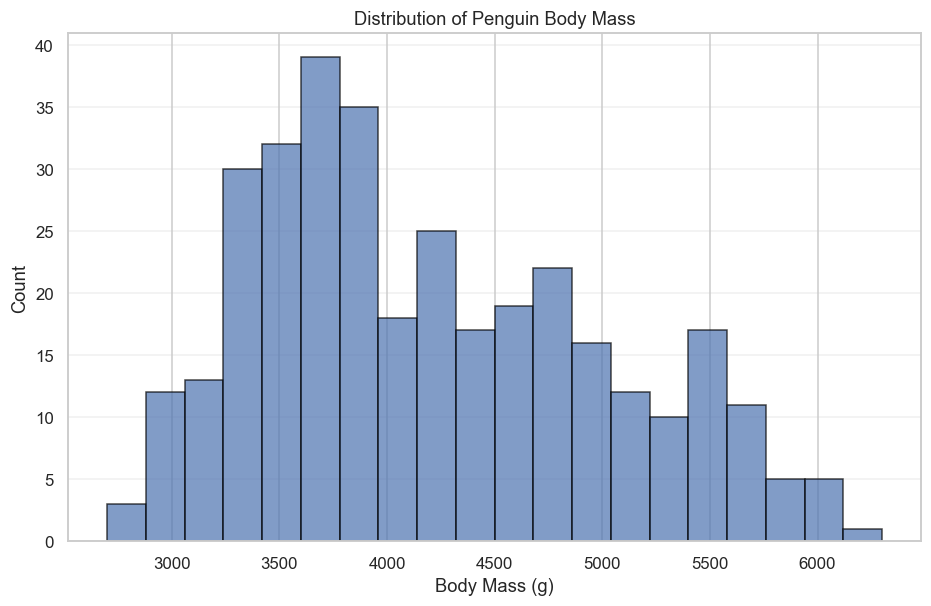

In [21]:
# Histogram
plt.figure(figsize=(10, 6))
df['body_mass_g'].hist(bins=20, edgecolor='black', alpha=0.7)
plt.title('Distribution of Penguin Body Mass')
plt.xlabel('Body Mass (g)')
plt.ylabel('Count')
plt.grid(axis='y', alpha=0.3)
plt.show()

**Histogram observation:**

The distribution shows **two distinct humps** — one around 3500-4000 g and another around 4700-5500 g. This is strong evidence of **hidden groups** in the data (which we'll learn are the different species).

---
✅ **Next:** `02_univariate_analysis.ipynb` — measuring and plotting one variable at a time.